# 2. Train: the released `noise` model

This notebook trains the released `noise` model (`swin_t_cnn_noise_10-20`) the way it was originally
trained:
- **Model:** a Swin-T backbone (starting from ImageNet weights) with CNN experts, on the
  `mnr_17leaf` taxonomy
- **Data:** up to 12,000 images per class from the class folders in `/data/Hier-Zooplankton` and
  `IssacData/`, plus all of `Quetico_training_data/`
- **Augmentation:** synthetic background noise (specks and fibres) on 80% of training images, plus
  random flips
- **Schedule:** 40 epochs, keeping the checkpoint with the best validation accuracy

It takes about 20 minutes on one GPU. `inference.ipynb` then tests the result on the Quetico
messy-background test set, next to the released weights.

**The result will be close to the released model but not identical.** Training on a GPU isn't fully
deterministic: re-running the original training script with the same seed doesn't reproduce its own
numbers exactly either. The last section compares this run with the released one.

To check that everything works before committing to the full run, set `QUICK = True`. That trains on
300 images per class for 3 epochs and takes a few minutes.

Requires `pip install hierroute jupyter`. The example data lives at `/data/Hier-Zooplankton` on the lab server; change `DATA_DIR` below if your copy is elsewhere. The trained run is saved in `training_result/` next to the folder this notebook is in (`../training_result/`, i.e. the repository's `training_result/` when run from `examples/`); change `TRAIN_DIR` to save it elsewhere.

In [6]:
from pathlib import Path

DATA_DIR = Path("/data/Hier-Zooplankton")        # example dataset (internal)
TRAIN_DIR = Path("../training_result").resolve()  # trained runs go here, relative to this notebook's folder

RUN_NAME = "swin_t_cnn_noise_example"   # run folder under TRAIN_DIR

## The taxonomy and how folders map onto it

A **hierarchy** defines the classes and how they nest. The released models use the bundled
`mnr_17leaf` hierarchy:
- every leaf class (one with no children) is read from a folder of the same name
- `folder_map` pools several folders into one class (e.g. `Bosminidae`, `Eubosmina` → `Bosmina`)

To use your own taxonomy, write a YAML file in the same format (see the README) and pass its path
instead of `"mnr_17leaf"`.

In [7]:
from hierroute.config import load_hierarchy

spec = load_hierarchy("mnr_17leaf")

def show(node, depth=0):
    print("    " * depth + node)
    for child in spec.tree[node]:
        show(child, depth + 1)

show("root")
print("\nfolder_map:")
for cls, folders in spec.folder_map.items():
    print(f"  {cls:18s} <- {folders}")

root
    Zoop-yes
        Copepoda
            Cyclopoid
            Calanoid
            Nauplius_Copepod
            Copepoda_Unknown
        Cladocera
            Bosmina
            Daphnia
            Holopedium
            Chydorus
            Diaphonosoma
            Cladocera_Unknown
        Rotifer
            Trichocerca
            Asplanchna
            Conochilus
            Kellicottia
            Rotifer_Unknown
        Zoop_Unknown
    Zoop-No

folder_map:
  Bosmina            <- ['Bosminidae', 'Bosmina_1', 'Eubosmina', 'Bosmina']
  Diaphonosoma       <- ['Diaphonosoma', 'Sididae']
  Zoop-No            <- ['Bubbles', 'Exoskeleton', 'Fiber_Squiggly', 'Fiber_Hairlike', 'Plant_Matter', 'Debris', 'Bubble', 'Detritus', 'Small_Organism_Single', 'Small_Organism_Multiple']
  Zoop_Unknown       <- ['Zooplankton', 'Emily_test_data/Zooplankton']
  Rotifer_Unknown    <- ['Rotifer']
  Copepoda_Unknown   <- ['Copepoda']
  Cladocera_Unknown  <- ['Cladocera']


## The training data

Training reads one folder per class from several places under `DATA_DIR`:

| Source | Setting | Use |
|---|---|---|
| class folders at the top of `DATA_DIR` | `data_dir` | capped at `max_class_size` per class, together with `IssacData` |
| `IssacData/` | `subdirectories` | same layout, pooled in |
| `Quetico_training_data/` | `uncapped_subdirectories` | Quetico debris and bubbles on messy backgrounds, always included in full |
| `Messy_background/moved_images/log.md` | `exclude_log` | lists images moved out to build a messy-background test set; they are skipped |

The table below counts the files on disk, before the cap and exclusions. The numbers actually used are
printed when training starts.

In [8]:
import pandas as pd

def count(base, cls):
    return sum(len(list((base / f).glob("*.tif"))) for f in spec.folder_map.get(cls, [cls])
               if (base / f).is_dir())

sources = {"top level": DATA_DIR, "IssacData": DATA_DIR / "IssacData",
           "Quetico_training_data": DATA_DIR / "Quetico_training_data"}
counts = pd.DataFrame({name: {cls: count(base, cls) for cls in spec.leaves} for name, base in sources.items()})
counts["total"] = counts.sum(axis=1)
counts.sort_values("total")

,top level,IssacData,Quetico_training_data,total
Zoop_Unknown,86,0,0,86
Copepoda_Unknown,593,0,0,593
Conochilus,799,0,0,799
Diaphonosoma,830,0,0,830
Cladocera_Unknown,995,0,0,995
Kellicottia,1136,0,0,1136
Trichocerca,1220,0,0,1220
Holopedium,1277,0,0,1277
Chydorus,1918,0,0,1918
Asplanchna,2483,0,0,2483


## Configure the run

These are the released model's settings, the same as `configs/mnr_swin_t_cnn_noise.yaml` in the
repository. `load_train_config` starts from the defaults (`TRAIN_DEFAULTS` in `hierroute/config.py`)
and applies the overrides. All settings are documented in the README.

The data is split 70 / 10 / 20 into train / validation / test, stratified by class with seed 666. With
the same data and settings you get the same split as the released model, so the test scores at the end
are directly comparable.

In [9]:
import yaml
from hierroute.config import load_train_config

config = load_train_config(overrides={
    "hierarchy": "mnr_17leaf",
    "model": {"backbone": "swin_t", "expert": "cnn", "loss": "bce"},
    "data": {
        "data_dir": str(DATA_DIR),
        "subdirectories": ["IssacData"],
        "uncapped_subdirectories": ["Quetico_training_data"],
        "exclude_log": "Messy_background/moved_images/log.md",
        "resolution": 64,
        "max_class_size": 12000,
        "split": [0.7, 0.1, 0.2],
        "balanced_sampling": True,        # inverse-frequency sampling of the training split
    },
    "augment": {"background_noise": True, "noise_p": 0.8, "hflip": True, "vflip": True},
    "train": {"lr": 3e-4, "max_epochs": 40, "scheduler": "cosine", "patience": 10, "delta": 0.001,
              "gradient_clip": 1.0, "batch_size": 64, "num_workers": 8, "seed": 666},
    "out_dir": str(TRAIN_DIR),
    "run_name": RUN_NAME,
})

QUICK = True                           # True: 300 images per class, 3 epochs (smoke test)
if QUICK:
    config["data"]["max_class_size"] = 300
    config["train"]["max_epochs"] = 3

print(yaml.safe_dump(config, sort_keys=False))

hierarchy: mnr_17leaf
model:
  backbone: swin_t
  expert: cnn
  loss: bce
  focal_gamma: 2.0
  freeze_backbone: false
  pretrained_backbone: true
data:
  data_dir: /data/Hier-Zooplankton
  subdirectories:
  - IssacData
  uncapped_subdirectories:
  - Quetico_training_data
  exclude_log: Messy_background/moved_images/log.md
  format: .tif
  resolution: 64
  max_class_size: 300
  split:
  - 0.7
  - 0.1
  - 0.2
  balanced_sampling: true
augment:
  background_noise: true
  noise_p: 0.8
  hflip: true
  vflip: true
train:
  lr: 0.0003
  max_epochs: 3
  scheduler: cosine
  patience: 10
  delta: 0.001
  gradient_clip: 1.0
  batch_size: 64
  num_workers: 8
  seed: 666
  device: auto
out_dir: /home/tjhinale/repo/Zooplankton_Classification/training_result
run_name: swin_t_cnn_noise_example



## Train

`train` builds the dataset, splits it, trains, then scores the held-out test split with the best
checkpoint. It returns the run folder, which contains:
- `best_model.pt`, the checkpoint
- `model_config.json`, so it loads like a released model
- `train_config.yaml`, `training_info.json`, `eval_results.json`, `predictions.npz`

An existing run folder is never overwritten; a `_1`, `_2`, … suffix is added instead. Delete an old
run (or change `RUN_NAME`) if you want `inference.ipynb` to pick up the new one.

In [10]:
from hierroute.train import train

run_dir = train(config)
run_dir

Hierarchy: mnr_17leaf | backbone: swin_t | expert: cnn | background noise: True
[leaves_only] Kept 6489 samples | Removed 0 non-leaf samples

Total Dataset: Size = 6489 | Levels = 3
all_node_counts: {0: 6489, 1: 4586, 3: 1200, 6: 300, 7: 300, 8: 300, 19: 300, 4: 1800, 9: 300, 10: 300, 11: 300, 12: 300, 13: 300, 20: 300, 5: 1500, 14: 300, 15: 300, 16: 300, 17: 300, 21: 300, 18: 86, 2: 1903}

nodes_by_level: {0: [0], 1: [1, 2], 2: [3, 4, 5, 18], 3: [6, 7, 8, 19, 9, 10, 11, 12, 13, 20, 14, 15, 16, 17, 21]}


------------------------Level 0------------------------
Level: 0 | Class Name: root                 | Class Label:   0 | Type: Parent | Count:   6489 | Prop: 1.00

------------------------Level 1------------------------
Level: 1 | Class Name: Zoop-yes             | Class Label:   1 | Type: Parent | Count:   4586 | Prop: 0.71
Level: 1 | Class Name: Zoop-No              | Class Label:   2 | Type: Leaf   | Count:   1903 | Prop: 0.29

------------------------Level 2-----------------------

PosixPath('/home/tjhinale/repo/Zooplankton_Classification/training_result/swin_t_cnn_noise_example')

## Results

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/swin_t_cnn_noise_example/train_metrics.png


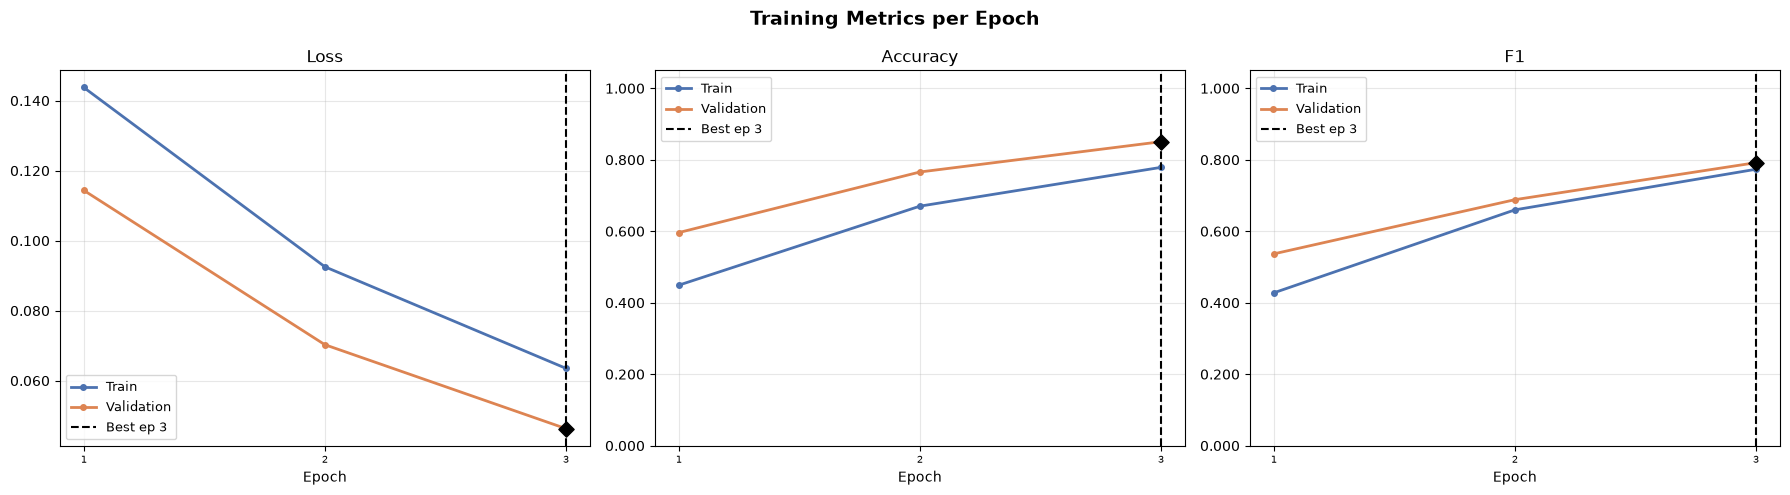

In [11]:
from hierroute import Visualize

vis = Visualize(run_dir)
vis.plot_train()          # loss / accuracy / F1 per epoch

Test-split scores of this run next to the released model's, on the same 14,345 test images. The
released scores come from the released checkpoint (its best epoch), scored the same way `train` scores
this run. Test images get the same random augmentation as training (synthetic dirt and flips), so
even re-scoring the same checkpoint moves the numbers slightly. Expect differences in the second or
third decimal place.

In [12]:
import json

# Released swin_t_cnn_noise_10-20: test-split scores of its best checkpoint
# (eval_results_best_checkpoint.json) and best epoch (training_info.json)
RELEASED = {1: {"accuracy": 0.9928, "f1": 0.9883},
            2: {"accuracy": 0.9868, "f1": 0.7409},
            3: {"accuracy": 0.9463, "f1": 0.9022}}
RELEASED_BEST = {"best_epoch": 38, "best_val_acc": 0.9543}

levels = json.loads((run_dir / "eval_results.json").read_text())["level_results"]
table = pd.DataFrame({
    f"level {d}": {"accuracy (this run)": r["overall"]["accuracy"],
                   "accuracy (released)": RELEASED[int(d)]["accuracy"],
                   "F1 (this run)": r["overall"]["f1"],
                   "F1 (released)": RELEASED[int(d)]["f1"],
                   "test images": r["overall"]["n_samples"]}
    for d, r in levels.items()}).T
best = json.loads((run_dir / "training_info.json").read_text())["results"]
print(f"best epoch {best['best_epoch']} (released {RELEASED_BEST['best_epoch']}), "
      f"best validation accuracy {best['best_val_acc']:.4f} (released {RELEASED_BEST['best_val_acc']})")
table.round(4)

best epoch 3 (released 38), best validation accuracy 0.8505 (released 0.9543)


,accuracy (this run),accuracy (released),F1 (this run),F1 (released),test images
level 1,0.9669,0.9928,0.9598,0.9883,1298.0
level 2,0.9084,0.9868,0.7152,0.7409,917.0
level 3,0.7911,0.9463,0.8024,0.9022,900.0


## Next

`inference.ipynb` evaluates this run and the released weights on the Quetico messy-background test set.
Any trained run is used exactly like a released model, by passing its folder as `weights`.

```bash
hierroute evaluate /data/Hier-Zooplankton/quetico/Messy --labelled \
    --weights training_result/swin_t_cnn_noise_example --out inference_result/quetico_messy_own_model_example
```

The same from the terminal, run from the repository root (where `configs/` and `training_result/` are):

```bash
hierroute train --config configs/mnr_swin_t_cnn_noise.yaml --data-dir /data/Hier-Zooplankton \
    --out-dir training_result --run-name swin_t_cnn_noise_example
```